Import packages and define cosmetic functions<br>
=================================================================================================

In [1]:
import os
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt
import matplotlib.gridspec as gs
import math
import uproot
from matplotlib.ticker import AutoMinorLocator

def style( ax ):
    ax.grid(which='major', axis='x', linewidth=0.2, linestyle='-', color='0.75')
    ax.grid(which='major', axis='y', linewidth=0.2, linestyle='-', color='0.75')
    ax.tick_params(which='major', length=8)
    ax.tick_params(which='minor', length=4)
    #ax.xaxis.set_minor_locator(AutoMinorLocator())
    #ax.yaxis.set_minor_locator(AutoMinorLocator())
    ax.spines['bottom'].set_linewidth(1)
    ax.spines['top'].set_linewidth(1)
    ax.spines['left'].set_linewidth(1)
    ax.spines['right'].set_linewidth(1)
    ax.margins(x=0)
    ax.legend(numpoints=1, ncol=1, prop={'size': 10.5}, frameon=False, loc='upper right')

def labels( ax, xlabel=None, ylabel=None ):
    if xlabel is not None:
        ax.set_xlabel(xlabel, size=14, horizontalalignment='right', x=1.0)
    if ylabel is not None:
        ax.set_ylabel(ylabel, size=14, horizontalalignment='right', y=1.0)

Read files and save information in dataframes<br>
=================================================================================================

In [2]:
# Abertura dos arquivos reais localizados em projeto_final para o canal e±μ±
Data_MuonEG_G_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/Data_MuonEG_G_1_16_files_0_28/Tree.root")
Data_MuonEG_H_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/Data_MuonEG_H_1_16_files_0_18/Tree.root")

DYJetsToLL_PtZ_3To50_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/DYJetsToLL_PtZ-3To50_1_16_files_0_124/Tree.root")
DYJetsToLL_PtZ_50To100_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/DYJetsToLL_PtZ-50To100_1_16_files_0_89/Tree.root")
DYJetsToLL_PtZ_100To250_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/DYJetsToLL_PtZ-100To250_1_16_files_0_75/Tree.root")
DYJetsToLL_PtZ_250To400_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/DYJetsToLL_PtZ-250To400_1_16_files_0_46/Tree.root")
DYJetsToLL_PtZ_400To650_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/DYJetsToLL_PtZ-400To650_1_16_files_0_17/Tree.root")
DYJetsToLL_PtZ_650ToInf_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/DYJetsToLL_PtZ-650ToInf_1_16_files_0_16/Tree.root")

TTTo2L2Nu_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/TTTo2L2Nu_1_16_files_0_48/Tree.root")
WWTo2L2Nu_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/WWTo2L2Nu_1_16_files_0_6/Tree.root")
ZZTo2L2Nu_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/ZZTo2L2Nu_1_16_files_0_14/Tree.root")

# Carregamento dos dados em formato de dicionário de DataFrames Pandas
ds = {}
ds["Data_MuonEG_G"] = Data_MuonEG_G_file["selection"].arrays(library="pd")
ds["Data_MuonEG_H"] = Data_MuonEG_H_file["selection"].arrays(library="pd")

ds["DYJetsToLL_PtZ_3To50"] = DYJetsToLL_PtZ_3To50_file["selection"].arrays(library="pd")
ds["DYJetsToLL_PtZ_50To100"] = DYJetsToLL_PtZ_50To100_file["selection"].arrays(library="pd")
ds["DYJetsToLL_PtZ_100To250"] = DYJetsToLL_PtZ_100To250_file["selection"].arrays(library="pd")
ds["DYJetsToLL_PtZ_250To400"] = DYJetsToLL_PtZ_250To400_file["selection"].arrays(library="pd")
ds["DYJetsToLL_PtZ_400To650"] = DYJetsToLL_PtZ_400To650_file["selection"].arrays(library="pd")
ds["DYJetsToLL_PtZ_650ToInf"] = DYJetsToLL_PtZ_650ToInf_file["selection"].arrays(library="pd")

ds["TTTo2L2Nu"] = TTTo2L2Nu_file["selection"].arrays(library="pd")
ds["WWTo2L2Nu"] = WWTo2L2Nu_file["selection"].arrays(library="pd")
ds["ZZTo2L2Nu"] = ZZTo2L2Nu_file["selection"].arrays(library="pd")

# ------------------------------------------------------------------------------------------------------------------------
# SALVANDO UMA CÓPIA DOS DADOS BRUTOS (ANTES DOS CORTES)
# ------------------------------------------------------------------------------------------------------------------------
ds_raw = {key: df.copy() for key, df in ds.items()}

# ------------------------------------------------------------------------------------------------------------------------
# APLICAÇÃO DOS CORTES
# ------------------------------------------------------------------------------------------------------------------------
print(f"{'Processo':<30} | {'Eventos Antes':<15} | {'Eventos Depois':<15}")
print("-" * 66)

for key in ds:
    df = ds[key]
    eventos_antes = len(df)
    
    # 1. Corte para eliminar TT (exigindo 0 b-jets)
    corte_tt = (df['Nbjets'] == 0)
    
    # 2. Corte na massa invariável em torno do Bóson Z (60 a 120 GeV)
    corte_massa = (df['LepLep_mass'] >= 60.0) & (df['LepLep_mass'] <= 120.0)
    
    # 3. Cortes mínimos de pT dos léptons mais suaves
    corte_pt = (df['LeadingLep_pt'] > 15.0) & (df['TrailingLep_pt'] > 10.0)
    
    # Aplicando a combinação de todas as seleções ativas
    selecao_final = corte_tt & corte_massa & corte_pt
    
    # Filtrando o DataFrame original diretamente
    ds[key] = df[selecao_final]
    eventos_depois = len(ds[key])
    
    print(f"{key:<30} | {eventos_antes:<15} | {eventos_depois:<15}")

Processo                       | Eventos Antes   | Eventos Depois 
------------------------------------------------------------------
Data_MuonEG_G                  | 35998           | 4655           
Data_MuonEG_H                  | 41448           | 5438           
DYJetsToLL_PtZ_3To50           | 4012            | 3543           
DYJetsToLL_PtZ_50To100         | 33035           | 28016          
DYJetsToLL_PtZ_100To250        | 99452           | 67883          
DYJetsToLL_PtZ_250To400        | 390372          | 246469         
DYJetsToLL_PtZ_400To650        | 155683          | 104078         
DYJetsToLL_PtZ_650ToInf        | 283466          | 198184         
TTTo2L2Nu                      | 866899          | 67805          
WWTo2L2Nu                      | 58910           | 20576          
ZZTo2L2Nu                      | 221644          | 189846         


Metadata and luminosity weight<br>
=================================================================================================

In [3]:
Data_luminosity = 16393.3805 # pb-¹

md = {} #                             [Cross section [pb], Generator weights sum]
md["DYJetsToLL_PtZ_3To50"] =    [1414,      123866571129.0938]
md["DYJetsToLL_PtZ_50To100"] =  [378.97,    46921372350.48828]
md["DYJetsToLL_PtZ_100To250"] = [93.1366,    6025316696.791992]
md["DYJetsToLL_PtZ_250To400"] = [3.7093,     152821361.0812912]
md["DYJetsToLL_PtZ_400To650"] = [0.515,      3369752.256501198]
md["DYJetsToLL_PtZ_650ToInf"] = [0.048934,   332449.5045676231]
md["TTTo2L2Nu"] =                [88.51,      721135180.715332]
md["WWTo2L2Nu"] =               [11.09,      32147079.16720963]
md["ZZTo2L2Nu"] =               [1.07118,    9737381.869026184]

print("=== COMPARAÇÃO DOS PESOS DE MONTE CARLO ===")
print(f"{'Processo / Amostra':<30} | {'Qtd. Eventos Brutos':<20} | {'Soma Ponderada (Após Pesos)':<25}")
print("-" * 82)

# Cálculo do peso de evento para normalização à luminosidade dos dados
for process in ds.keys(): 
    if process[:4] != "Data":
        # Contagem de eventos antes dos pesos
        eventos_brutos = len(ds[process])
        
        # Aplicação do peso
        ds[process]["evtWeight"] = ds[process]["genWeight"] * (md[process][0] * Data_luminosity / md[process][1])
        
        # Soma total dos pesos (número efetivo de eventos normalizados)
        soma_pesos = ds[process]["evtWeight"].sum()
        
        print(f"{process:<30} | {eventos_brutos:<20} | {soma_pesos:<25.2f}")
    else:
        # Dados reais não usam evtWeight (peso é 1.0)
        eventos_data = len(ds[process])
        print(f"{process:<30} | {eventos_data:<20} | {float(eventos_data):<25.2f} (Dados Reais)")

print("-" * 82)

# Agrupamento dos datasets por tipo de processo físico
ds["Data"] = pd.concat([ds["Data_MuonEG_G"], ds["Data_MuonEG_H"]]).reset_index(drop=True)
del ds["Data_MuonEG_G"], ds["Data_MuonEG_H"]

ds["DYJetsToLL"] = pd.concat([
    ds["DYJetsToLL_PtZ_3To50"], ds["DYJetsToLL_PtZ_50To100"], 
    ds["DYJetsToLL_PtZ_100To250"], ds["DYJetsToLL_PtZ_250To400"], 
    ds["DYJetsToLL_PtZ_400To650"], ds["DYJetsToLL_PtZ_650ToInf"]
]).reset_index(drop=True)
del ds["DYJetsToLL_PtZ_3To50"], ds["DYJetsToLL_PtZ_50To100"], ds["DYJetsToLL_PtZ_100To250"], ds["DYJetsToLL_PtZ_250To400"], ds["DYJetsToLL_PtZ_400To650"], ds["DYJetsToLL_PtZ_650ToInf"]

ds["TT"] = ds["TTTo2L2Nu"].copy()
del ds["TTTo2L2Nu"]

ds["VV"] = pd.concat([ds["WWTo2L2Nu"], ds["ZZTo2L2Nu"]]).reset_index(drop=True)
del ds["WWTo2L2Nu"], ds["ZZTo2L2Nu"]

print("Total de eventos ponderados no DY unificado:", ds["DYJetsToLL"]["evtWeight"].sum())

=== COMPARAÇÃO DOS PESOS DE MONTE CARLO ===
Processo / Amostra             | Qtd. Eventos Brutos  | Soma Ponderada (Após Pesos)
----------------------------------------------------------------------------------
Data_MuonEG_G                  | 4655                 | 4655.00                   (Dados Reais)
Data_MuonEG_H                  | 5438                 | 5438.00                   (Dados Reais)
DYJetsToLL_PtZ_3To50           | 3543                 | 6681.44                  
DYJetsToLL_PtZ_50To100         | 28016                | 17637.11                 
DYJetsToLL_PtZ_100To250        | 67883                | 10559.89                 
DYJetsToLL_PtZ_250To400        | 246469               | 1508.85                  
DYJetsToLL_PtZ_400To650        | 104078               | 444.93                   
DYJetsToLL_PtZ_650ToInf        | 198184               | 78.53                    
TTTo2L2Nu                      | 67805                | 9860.51                  
WWTo2L2Nu              

Check trigger efficiency plots<br>
=================================================================================================

/tmp/ipykernel_12500/3923944257.py:41: RuntimeWarning: invalid value encountered in divide
  TT_efficiency = np.array(TT_numerator)/np.array(TT_denominator)
/tmp/ipykernel_12500/3923944257.py:45: RuntimeWarning: invalid value encountered in divide
  Data_efficiency = np.array(Data_numerator)/np.array(Data_denominator)
/tmp/ipykernel_12500/3923944257.py:82: RuntimeWarning: invalid value encountered in divide
  TT_efficiency = np.array(TT_numerator)/np.array(TT_denominator)
/tmp/ipykernel_12500/3923944257.py:85: RuntimeWarning: invalid value encountered in divide
  Data_efficiency = np.array(Data_numerator)/np.array(Data_denominator)


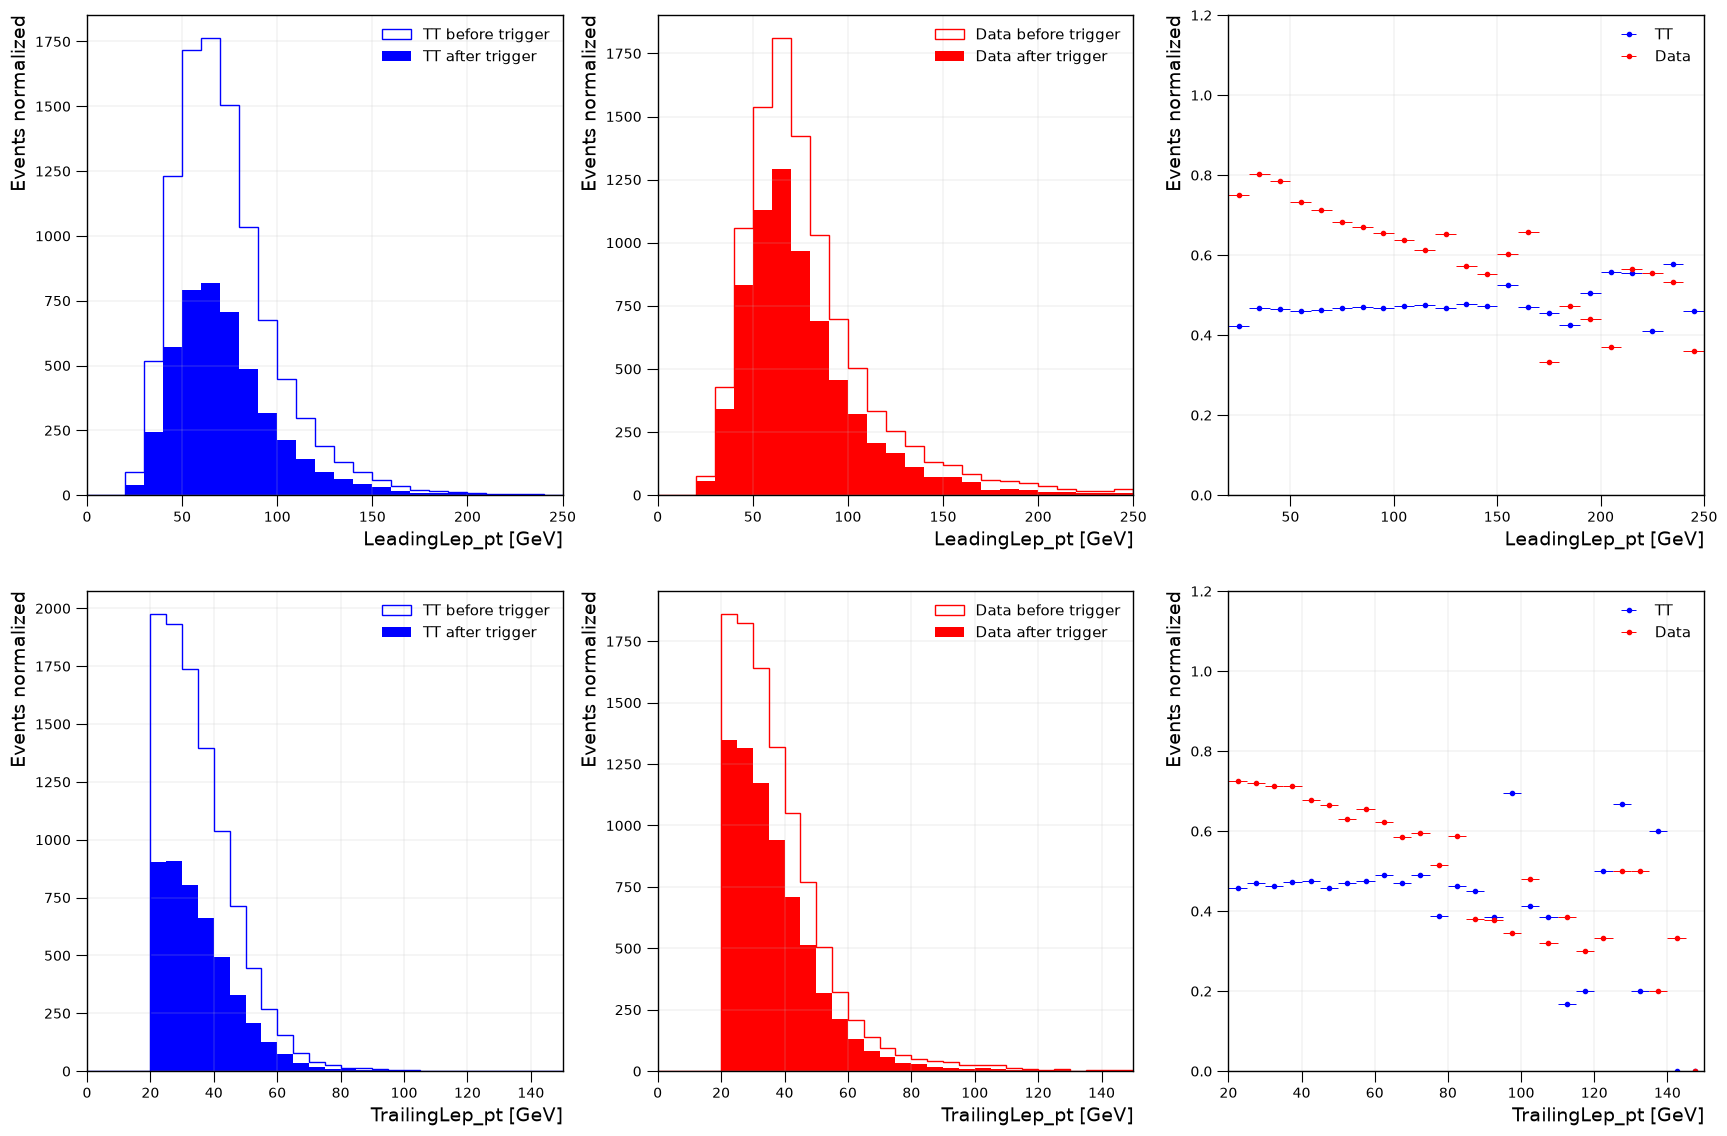

In [4]:
# Cria uma figura grande dividida em uma grade de 2 linhas por 3 colunas
fig1 = plt.figure(figsize=(21,12))
grid = [2, 3]
gs1 = gs.GridSpec(grid[0], grid[1])

# ==================================================================================================
# LINHA 1: ANÁLISE DO LÉPTON PRINCIPAL (LeadingLep_pt)
# ==================================================================================================

# 1. Painel esquerdo: Simulação (TT) - Antes e Depois do Trigger para o LeadingLep_pt
ax1 = plt.subplot(gs1[0])
var = "LeadingLep_pt"
bins = np.linspace(0.,250,26)
# Denominador: Todos os eventos de TT (antes do trigger)
TT_denominator, b_dummy, p_dummy = plt.hist(ds["TT"][var], bins=bins, weights=ds["TT"]["evtWeight"], color='blue', histtype='step', label="TT before trigger")
# Numerador: Apenas os eventos de TT que passaram pelo gatilho HLT_EleMu
TT_numerator, b_dummy, p_dummy = plt.hist(ds["TT"][ds["TT"]["HLT_EleMu"]][var], bins=bins, weights=ds["TT"][ds["TT"]["HLT_EleMu"]]["evtWeight"], color='blue', histtype='stepfilled', label="TT after trigger")
style(ax1)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Events normalized")

# 2. Painel central: Dados Reais (Data) - Antes e Depois do Trigger para o LeadingLep_pt
ax1 = plt.subplot(gs1[1])
var = "LeadingLep_pt"
bins = np.linspace(0.,250,26)
# Denominador: Todos os eventos reais coletados
Data_denominator, b_dummy, p_dummy = plt.hist(ds["Data"][var], bins=bins, weights=ds["Data"]["evtWeight"], color='red', histtype='step', label="Data before trigger")
# Numerador: Apenas os eventos reais que ativaram o HLT_EleMu
Data_numerator, b_dummy, p_dummy = plt.hist(ds["Data"][ds["Data"]["HLT_EleMu"]][var], bins=bins, weights=ds["Data"][ds["Data"]["HLT_EleMu"]]["evtWeight"], color='red', histtype='stepfilled', label="Data after trigger")
style(ax1)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Events normalized")

# 3. Painel direito: Curva de Eficiência do Trigger para o LeadingLep_pt (Data vs TT)
ax1 = plt.subplot(gs1[2])
var = "LeadingLep_pt"
bins = np.linspace(0.,250,26)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx

# Calcula a eficiência dividindo o numerador pelo denominador para TT e plota com barras de erro
TT_efficiency = np.array(TT_numerator)/np.array(TT_denominator)
ax1.errorbar(x_mean, TT_efficiency, xerr=0.5*dx, fmt='.', ecolor='blue', color='blue', elinewidth=0.7, capsize=0, label="TT")

# Calcula a eficiência para os Dados Reais e plota comparativamente
Data_efficiency = np.array(Data_numerator)/np.array(Data_denominator)
ax1.errorbar(x_mean, Data_efficiency, xerr=0.5*dx, fmt='.', ecolor='red', color='red', elinewidth=0.7, capsize=0, label="Data")

plt.ylim(0, 1.2)
style(ax1)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Events normalized")

# ==================================================================================================
# LINHA 2: ANÁLISE DO LÉPTON SECUNDÁRIO (TrailingLep_pt)
# ==================================================================================================

# 4. Painel esquerdo inferior: Simulação (TT) - Antes e Depois do Trigger para o TrailingLep_pt
ax1 = plt.subplot(gs1[3])
var = "TrailingLep_pt"
bins = np.linspace(0.,150,31)
TT_denominator, b_dummy, p_dummy = plt.hist(ds["TT"][var], bins=bins, weights=ds["TT"]["evtWeight"], color='blue', histtype='step', label="TT before trigger")
TT_numerator, b_dummy, p_dummy = plt.hist(ds["TT"][ds["TT"]["HLT_EleMu"]][var], bins=bins, weights=ds["TT"][ds["TT"]["HLT_EleMu"]]["evtWeight"], color='blue', histtype='stepfilled', label="TT after trigger")
style(ax1)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Events normalized")

# 5. Painel central inferior: Dados Reais (Data) - Antes e Depois do Trigger para o TrailingLep_pt
ax1 = plt.subplot(gs1[4])
var = "TrailingLep_pt"
bins = np.linspace(0.,150,31)
Data_denominator, b_dummy, p_dummy = plt.hist(ds["Data"][var], bins=bins, weights=ds["Data"]["evtWeight"], color='red', histtype='step', label="Data before trigger")
Data_numerator, b_dummy, p_dummy = plt.hist(ds["Data"][ds["Data"]["HLT_EleMu"]][var], bins=bins, weights=ds["Data"][ds["Data"]["HLT_EleMu"]]["evtWeight"], color='red', histtype='stepfilled', label="Data after trigger")
style(ax1)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Events normalized")

# 6. Painel direito inferior: Curva de Eficiência do Trigger para o TrailingLep_pt (Data vs TT)
ax1 = plt.subplot(gs1[5])
var = "TrailingLep_pt"
bins = np.linspace(0.,150,31)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx

TT_efficiency = np.array(TT_numerator)/np.array(TT_denominator)
ax1.errorbar(x_mean, TT_efficiency, xerr=0.5*dx, fmt='.', ecolor='blue', color='blue', elinewidth=0.7, capsize=0, label="TT")

Data_efficiency = np.array(Data_numerator)/np.array(Data_denominator)
ax1.errorbar(x_mean, Data_efficiency, xerr=0.5*dx, fmt='.', ecolor='red', color='red', elinewidth=0.7, capsize=0, label="Data")

plt.ylim(0, 1.2)
style(ax1)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Events normalized")

# ==================================================================================================
# AJUSTES FINAIS E SALVAMENTO
# ==================================================================================================
plt.subplots_adjust(left=0.2, bottom=0.085, right=0.97, top=0.965, wspace=0.2, hspace=0.2)
plt.savefig('efficiency_plots.pdf')
plt.savefig('efficiency_plots.png', dpi=400)

/tmp/ipykernel_12500/141467245.py:41: RuntimeWarning: invalid value encountered in divide
  VV_efficiency = np.array(VV_numerator)/np.array(VV_denominator)
/tmp/ipykernel_12500/141467245.py:45: RuntimeWarning: invalid value encountered in divide
  Data_efficiency = np.array(Data_numerator)/np.array(Data_denominator)
/tmp/ipykernel_12500/141467245.py:82: RuntimeWarning: invalid value encountered in divide
  VV_efficiency = np.array(VV_numerator)/np.array(VV_denominator)
/tmp/ipykernel_12500/141467245.py:85: RuntimeWarning: invalid value encountered in divide
  Data_efficiency = np.array(Data_numerator)/np.array(Data_denominator)


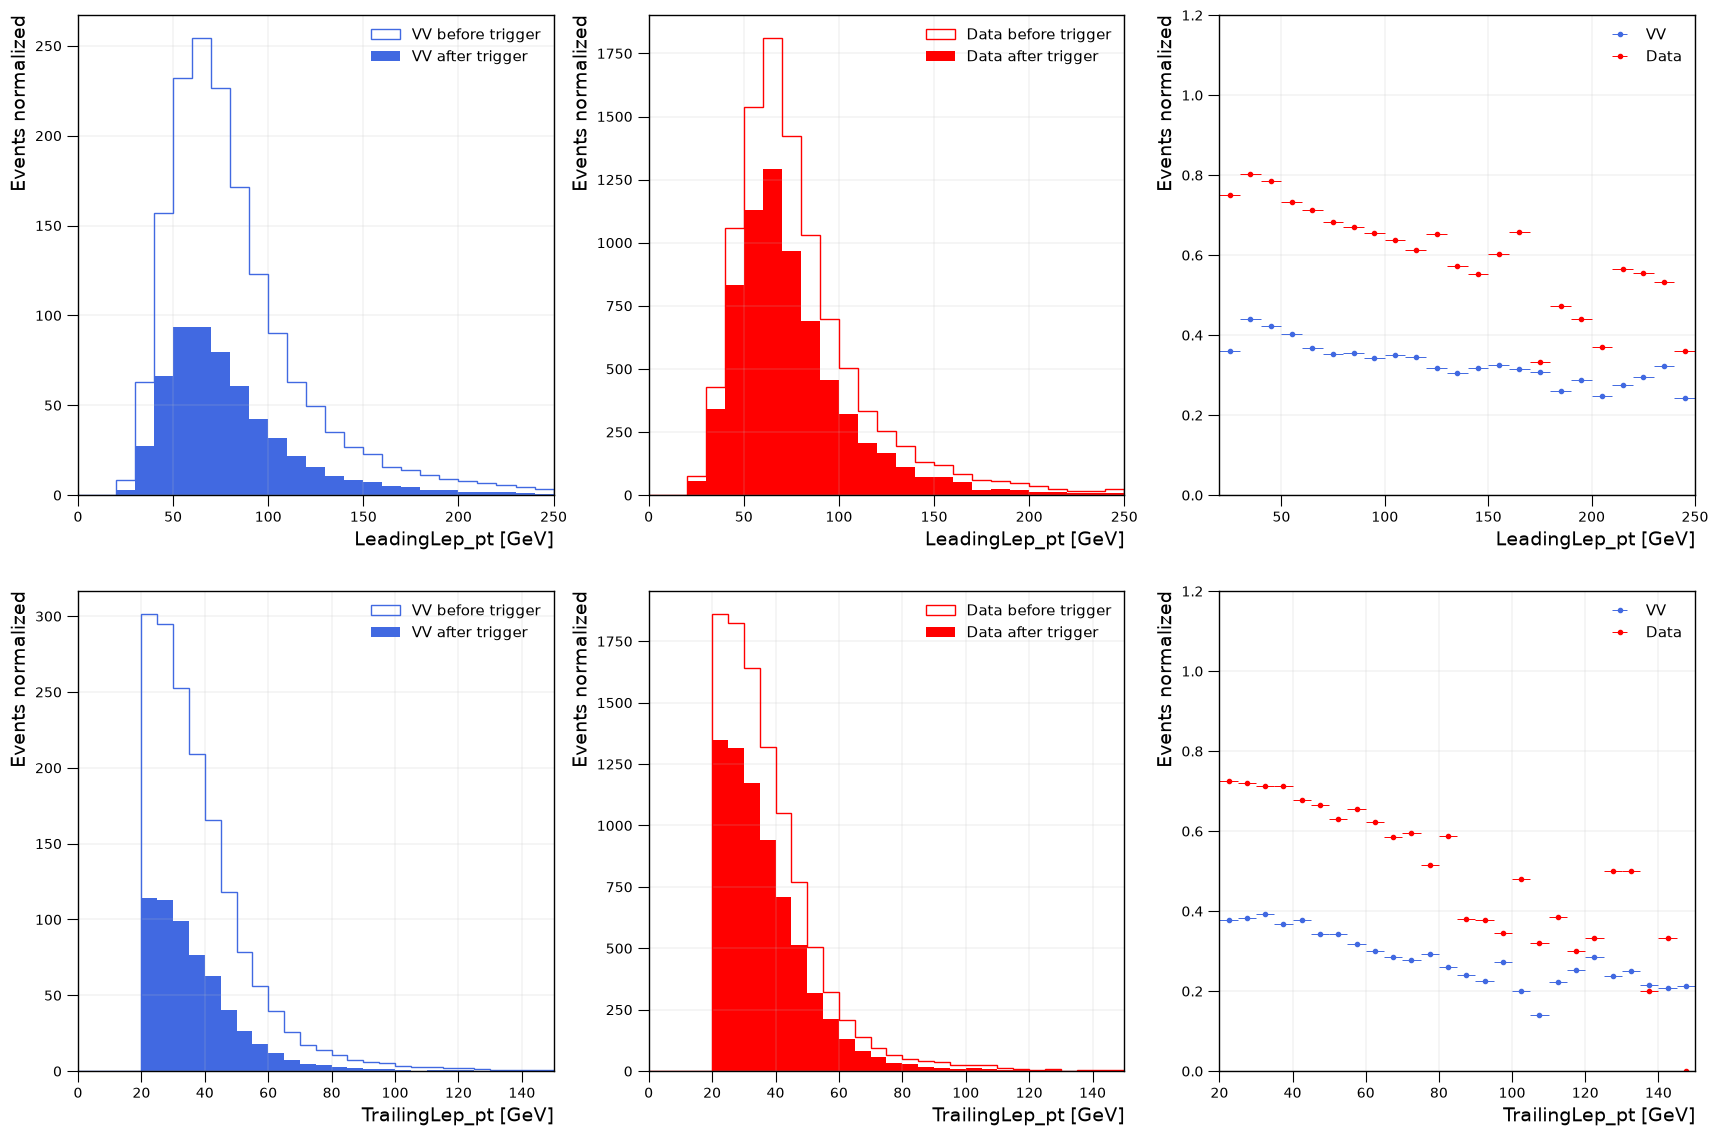

In [5]:
# Cria uma figura grande dividida em uma grade de 2 linhas por 3 colunas
fig1 = plt.figure(figsize=(21,12))
grid = [2, 3]
gs1 = gs.GridSpec(grid[0], grid[1])

# ==================================================================================================
# LINHA 1: ANÁLISE DO LÉPTON PRINCIPAL (LeadingLep_pt) - VV vs Data
# ==================================================================================================

# 1. Painel esquerdo: Simulação (VV) - Antes e Depois do Trigger para o LeadingLep_pt
ax1 = plt.subplot(gs1[0])
var = "LeadingLep_pt"
bins = np.linspace(0.,250,26)
# Denominador: Todos os eventos de VV (antes do trigger)
VV_denominator, b_dummy, p_dummy = plt.hist(ds["VV"][var], bins=bins, weights=ds["VV"]["evtWeight"], color='royalblue', histtype='step', label="VV before trigger")
# Numerador: Apenas os eventos de VV que passaram pelo gatilho HLT_EleMu
VV_numerator, b_dummy, p_dummy = plt.hist(ds["VV"][ds["VV"]["HLT_EleMu"]][var], bins=bins, weights=ds["VV"][ds["VV"]["HLT_EleMu"]]["evtWeight"], color='royalblue', histtype='stepfilled', label="VV after trigger")
style(ax1)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Events normalized")

# 2. Painel central: Dados Reais (Data) - Antes e Depois do Trigger para o LeadingLep_pt
ax1 = plt.subplot(gs1[1])
var = "LeadingLep_pt"
bins = np.linspace(0.,250,26)
# Denominador: Todos os eventos reais coletados (sem peso de gerador)
Data_denominator, b_dummy, p_dummy = plt.hist(ds["Data"][var], bins=bins, color='red', histtype='step', label="Data before trigger")
# Numerador: Apenas os eventos reais que ativaram o HLT_EleMu
Data_numerator, b_dummy, p_dummy = plt.hist(ds["Data"][ds["Data"]["HLT_EleMu"]][var], bins=bins, color='red', histtype='stepfilled', label="Data after trigger")
style(ax1)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Events normalized")

# 3. Painel direito: Curva de Eficiência do Trigger para o LeadingLep_pt (VV vs Data)
ax1 = plt.subplot(gs1[2])
var = "LeadingLep_pt"
bins = np.linspace(0.,250,26)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx

# Calcula a eficiência dividindo o numerador pelo denominador para VV e plota com barras de erro
VV_efficiency = np.array(VV_numerator)/np.array(VV_denominator)
ax1.errorbar(x_mean, VV_efficiency, xerr=0.5*dx, fmt='.', ecolor='royalblue', color='royalblue', elinewidth=0.7, capsize=0, label="VV")

# Calcula a eficiência para os Dados Reais e plota comparativamente
Data_efficiency = np.array(Data_numerator)/np.array(Data_denominator)
ax1.errorbar(x_mean, Data_efficiency, xerr=0.5*dx, fmt='.', ecolor='red', color='red', elinewidth=0.7, capsize=0, label="Data")

plt.ylim(0, 1.2)
style(ax1)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Events normalized")

# ==================================================================================================
# LINHA 2: ANÁLISE DO LÉPTON SECUNDÁRIO (TrailingLep_pt) - VV vs Data
# ==================================================================================================

# 4. Painel esquerdo inferior: Simulação (VV) - Antes e Depois do Trigger para o TrailingLep_pt
ax1 = plt.subplot(gs1[3])
var = "TrailingLep_pt"
bins = np.linspace(0.,150,31)
VV_denominator, b_dummy, p_dummy = plt.hist(ds["VV"][var], bins=bins, weights=ds["VV"]["evtWeight"], color='royalblue', histtype='step', label="VV before trigger")
VV_numerator, b_dummy, p_dummy = plt.hist(ds["VV"][ds["VV"]["HLT_EleMu"]][var], bins=bins, weights=ds["VV"][ds["VV"]["HLT_EleMu"]]["evtWeight"], color='royalblue', histtype='stepfilled', label="VV after trigger")
style(ax1)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Events normalized")

# 5. Painel central inferior: Dados Reais (Data) - Antes e Depois do Trigger para o TrailingLep_pt
ax1 = plt.subplot(gs1[4])
var = "TrailingLep_pt"
bins = np.linspace(0.,150,31)
Data_denominator, b_dummy, p_dummy = plt.hist(ds["Data"][var], bins=bins, color='red', histtype='step', label="Data before trigger")
Data_numerator, b_dummy, p_dummy = plt.hist(ds["Data"][ds["Data"]["HLT_EleMu"]][var], bins=bins, color='red', histtype='stepfilled', label="Data after trigger")
style(ax1)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Events normalized")

# 6. Painel direito inferior: Curva de Eficiência do Trigger para o TrailingLep_pt (VV vs Data)
ax1 = plt.subplot(gs1[5])
var = "TrailingLep_pt"
bins = np.linspace(0.,150,31)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx

VV_efficiency = np.array(VV_numerator)/np.array(VV_denominator)
ax1.errorbar(x_mean, VV_efficiency, xerr=0.5*dx, fmt='.', ecolor='royalblue', color='royalblue', elinewidth=0.7, capsize=0, label="VV")

Data_efficiency = np.array(Data_numerator)/np.array(Data_denominator)
ax1.errorbar(x_mean, Data_efficiency, xerr=0.5*dx, fmt='.', ecolor='red', color='red', elinewidth=0.7, capsize=0, label="Data")

plt.ylim(0, 1.2)
style(ax1)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Events normalized")

# ==================================================================================================
# AJUSTES FINAIS E SALVAMENTO
# ==================================================================================================
plt.subplots_adjust(left=0.2, bottom=0.085, right=0.97, top=0.965, wspace=0.2, hspace=0.2)
plt.savefig('efficiency_plots_VV_Data.pdf')
plt.savefig('efficiency_plots_VV_Data.png', dpi=400)

/tmp/ipykernel_12500/2338997418.py:41: RuntimeWarning: invalid value encountered in divide
  DY_efficiency = np.array(DY_numerator)/np.array(DY_denominator)
/tmp/ipykernel_12500/2338997418.py:45: RuntimeWarning: invalid value encountered in divide
  Data_efficiency = np.array(Data_numerator)/np.array(Data_denominator)
/tmp/ipykernel_12500/2338997418.py:82: RuntimeWarning: invalid value encountered in divide
  DY_efficiency = np.array(DY_numerator)/np.array(DY_denominator)
/tmp/ipykernel_12500/2338997418.py:85: RuntimeWarning: invalid value encountered in divide
  Data_efficiency = np.array(Data_numerator)/np.array(Data_denominator)


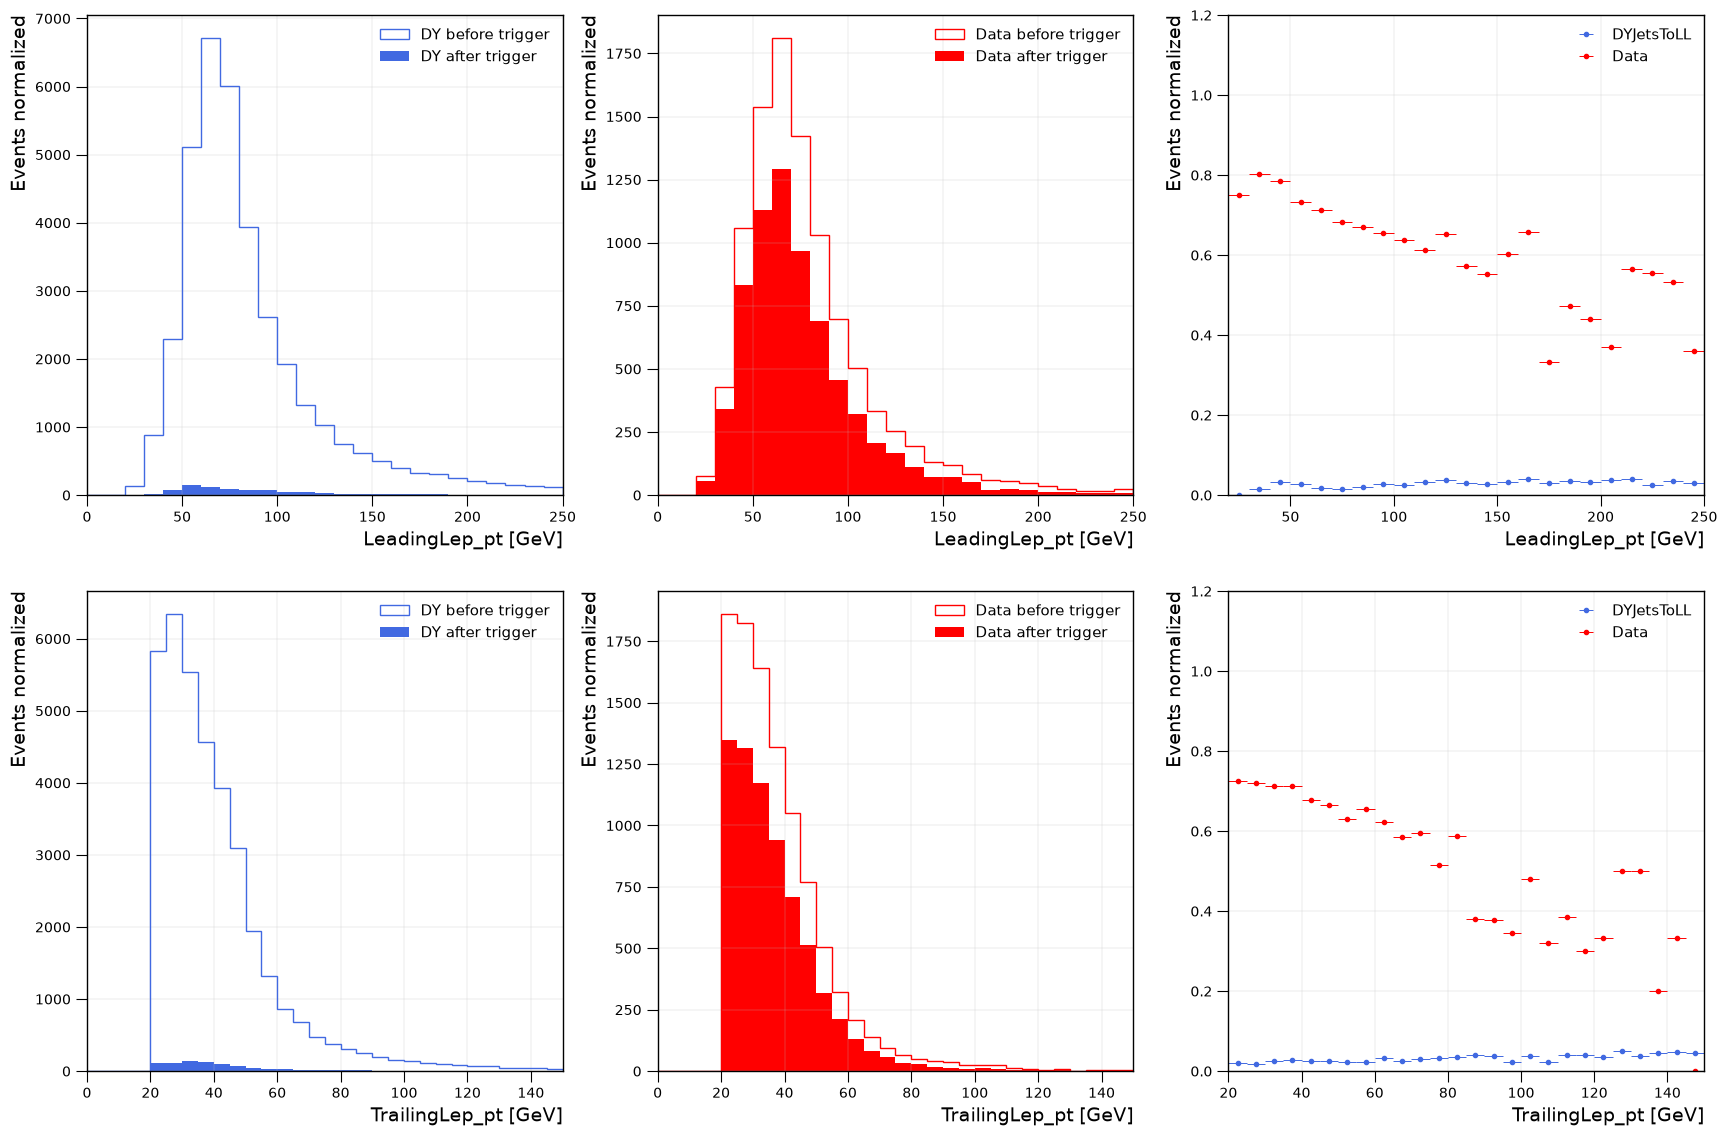

In [6]:
# Cria uma figura grande dividida em uma grade de 2 linhas por 3 colunas
fig1 = plt.figure(figsize=(21,12))
grid = [2, 3]
gs1 = gs.GridSpec(grid[0], grid[1])

# ==================================================================================================
# LINHA 1: ANÁLISE DO LÉPTON PRINCIPAL (LeadingLep_pt) - DYJetsToLL vs Data
# ==================================================================================================

# 1. Painel esquerdo: Simulação (DYJetsToLL) - Antes e Depois do Trigger para o LeadingLep_pt
ax1 = plt.subplot(gs1[0])
var = "LeadingLep_pt"
bins = np.linspace(0.,250,26)
# Denominador: Todos os eventos de DYJetsToLL (antes do trigger)
DY_denominator, b_dummy, p_dummy = plt.hist(ds["DYJetsToLL"][var], bins=bins, weights=ds["DYJetsToLL"]["evtWeight"], color='royalblue', histtype='step', label="DY before trigger")
# Numerador: Apenas os eventos de DYJetsToLL que passaram pelo gatilho HLT_EleMu
DY_numerator, b_dummy, p_dummy = plt.hist(ds["DYJetsToLL"][ds["DYJetsToLL"]["HLT_EleMu"]][var], bins=bins, weights=ds["DYJetsToLL"][ds["DYJetsToLL"]["HLT_EleMu"]]["evtWeight"], color='royalblue', histtype='stepfilled', label="DY after trigger")
style(ax1)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Events normalized")

# 2. Painel central: Dados Reais (Data) - Antes e Depois do Trigger para o LeadingLep_pt
ax1 = plt.subplot(gs1[1])
var = "LeadingLep_pt"
bins = np.linspace(0.,250,26)
# Denominador: Todos os eventos reais coletados (sem peso de gerador)
Data_denominator, b_dummy, p_dummy = plt.hist(ds["Data"][var], bins=bins, color='red', histtype='step', label="Data before trigger")
# Numerador: Apenas os eventos reais que ativaram o HLT_EleMu
Data_numerator, b_dummy, p_dummy = plt.hist(ds["Data"][ds["Data"]["HLT_EleMu"]][var], bins=bins, color='red', histtype='stepfilled', label="Data after trigger")
style(ax1)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Events normalized")

# 3. Painel direito: Curva de Eficiência do Trigger para o LeadingLep_pt (DY vs Data)
ax1 = plt.subplot(gs1[2])
var = "LeadingLep_pt"
bins = np.linspace(0.,250,26)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx

# Calcula a eficiência dividindo o numerador pelo denominador para DY e plota com barras de erro
DY_efficiency = np.array(DY_numerator)/np.array(DY_denominator)
ax1.errorbar(x_mean, DY_efficiency, xerr=0.5*dx, fmt='.', ecolor='royalblue', color='royalblue', elinewidth=0.7, capsize=0, label="DYJetsToLL")

# Calcula a eficiência para os Dados Reais e plota comparativamente
Data_efficiency = np.array(Data_numerator)/np.array(Data_denominator)
ax1.errorbar(x_mean, Data_efficiency, xerr=0.5*dx, fmt='.', ecolor='red', color='red', elinewidth=0.7, capsize=0, label="Data")

plt.ylim(0, 1.2)
style(ax1)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Events normalized")

# ==================================================================================================
# LINHA 2: ANÁLISE DO LÉPTON SECUNDÁRIO (TrailingLep_pt) - DYJetsToLL vs Data
# ==================================================================================================

# 4. Painel esquerdo inferior: Simulação (DYJetsToLL) - Antes e Depois do Trigger para o TrailingLep_pt
ax1 = plt.subplot(gs1[3])
var = "TrailingLep_pt"
bins = np.linspace(0.,150,31)
DY_denominator, b_dummy, p_dummy = plt.hist(ds["DYJetsToLL"][var], bins=bins, weights=ds["DYJetsToLL"]["evtWeight"], color='royalblue', histtype='step', label="DY before trigger")
DY_numerator, b_dummy, p_dummy = plt.hist(ds["DYJetsToLL"][ds["DYJetsToLL"]["HLT_EleMu"]][var], bins=bins, weights=ds["DYJetsToLL"][ds["DYJetsToLL"]["HLT_EleMu"]]["evtWeight"], color='royalblue', histtype='stepfilled', label="DY after trigger")
style(ax1)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Events normalized")

# 5. Painel central inferior: Dados Reais (Data) - Antes e Depois do Trigger para o TrailingLep_pt
ax1 = plt.subplot(gs1[4])
var = "TrailingLep_pt"
bins = np.linspace(0.,150,31)
Data_denominator, b_dummy, p_dummy = plt.hist(ds["Data"][var], bins=bins, color='red', histtype='step', label="Data before trigger")
Data_numerator, b_dummy, p_dummy = plt.hist(ds["Data"][ds["Data"]["HLT_EleMu"]][var], bins=bins, color='red', histtype='stepfilled', label="Data after trigger")
style(ax1)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Events normalized")

# 6. Painel direito inferior: Curva de Eficiência do Trigger para o TrailingLep_pt (DY vs Data)
ax1 = plt.subplot(gs1[5])
var = "TrailingLep_pt"
bins = np.linspace(0.,150,31)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx

DY_efficiency = np.array(DY_numerator)/np.array(DY_denominator)
ax1.errorbar(x_mean, DY_efficiency, xerr=0.5*dx, fmt='.', ecolor='royalblue', color='royalblue', elinewidth=0.7, capsize=0, label="DYJetsToLL")

Data_efficiency = np.array(Data_numerator)/np.array(Data_denominator)
ax1.errorbar(x_mean, Data_efficiency, xerr=0.5*dx, fmt='.', ecolor='red', color='red', elinewidth=0.7, capsize=0, label="Data")

plt.ylim(0, 1.2)
style(ax1)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Events normalized")

# ==================================================================================================
# AJUSTES FINAIS E SALVAMENTO
# ==================================================================================================
plt.subplots_adjust(left=0.2, bottom=0.085, right=0.97, top=0.965, wspace=0.2, hspace=0.2)
plt.savefig('efficiency_plots_DY_Data.pdf')
plt.savefig('efficiency_plots_DY_Data.png', dpi=400)

Make plots<br>
=================================================================================================

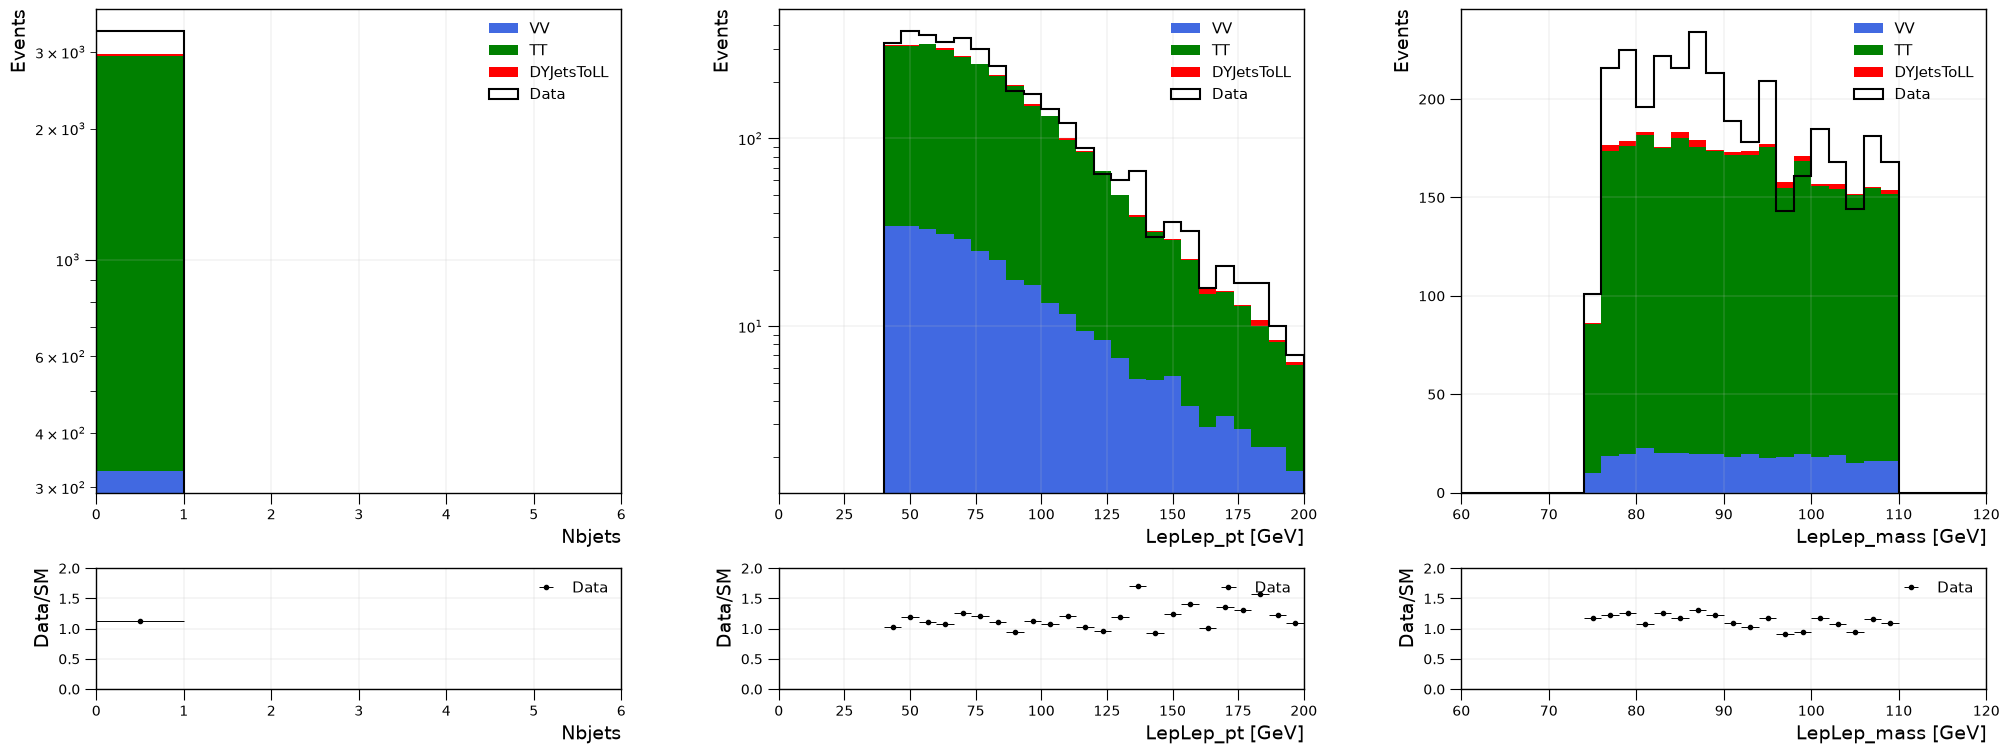

In [7]:
# ==========================================
# APLICAÇÃO DOS CORTES DE SELEÇÃO FÍSICA (Otimizado para o Sinal DY)
# ==========================================
df = {}
for process in ds.keys():
    df[process] = ds[process].copy()
    
    # Cortes otimizados para maximizar o sinal DY nas faixas principais
    df[process] = df[process][
        (df[process]["HLT_EleMu"] == True) & 
        (df[process]["RecoLepID"] > 100) & 
        (df[process]["Nbjets"] == 0) &                   # Elimina o fundo de TT
        (df[process]["LepLep_mass"] >= 75.0) &           # Janela centrada no Bóson Z (75 a 110 GeV)
        (df[process]["LepLep_mass"] <= 110.0) &
        (df[process]["LepLep_pt"] > 20.0) &              # Limiar seguro para os léptons
        (df[process]["LepLep_pt"] < 200.0)               # <--- NOVO CORTE: Foca onde o DY é massivo e limpa as caudas ruidosas
        ]
    
# O restante da sua plotagem (figura, subplots, histogramas e razão) permanece exatamente igual abaixo deste bloco.

# ==========================================
# CONFIGURAÇÃO DA FIGURA E DOS PAINÉIS (Ajustado)
# ==========================================
fig1 = plt.figure(figsize=(21, 8))  # Aumentamos um pouco a largura para caber os 3 painéis confortavelmente
grid = [2, 3]
gs1 = gs.GridSpec(grid[0], grid[1], height_ratios=[4, 1], wspace=0.3, hspace=0.25)

# ==========================================
# 1º GRUPO: VARIÁVEL "Nbjets" (Número de b-jatos)
# ==========================================
ax1 = plt.subplot(gs1[0])
var = "Nbjets"
bins = np.linspace(0.,6,7)
SM_values = [df["VV"][var], df["TT"][var], df["DYJetsToLL"][var]]
SM_weights = [df["VV"]["evtWeight"], df["TT"]["evtWeight"], df["DYJetsToLL"]["evtWeight"]]
SM_labels = ["VV", "TT", "DYJetsToLL"]
SM_colors = ['royalblue', 'green', "red"]

# Plota os histogramas empilhados (stacked=True) da simulação (Modelo Padrão)
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
# Plota os dados reais como uma linha preta em forma de escada (step)
Data_hist, b_dummy, p_dummy = plt.hist( df["Data"][var], bins=bins, linewidth=1.5, label='Data', color='black', histtype="step" )
plt.yscale("log") # Escala logarítmica para melhor visualização
style(ax1)
labels( ax1, xlabel="Nbjets", ylabel="Events")

# Painel inferior: Razão entre os Dados Reais e o Modelo Padrão (Data / SM)
ax1 = plt.subplot(gs1[3])
ratio = np.divide(Data_hist, SM_hist[-1], out=np.zeros_like(Data_hist, dtype=float)+9999999, where=SM_hist[-1] != 0)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, fmt='.', ecolor='black', color='black', elinewidth=0.7, capsize=0, label="Data")
plt.ylim(0., 2.0)
style(ax1)
labels( ax1, xlabel="Nbjets", ylabel="Data/SM")

# ==========================================
# 2º GRUPO: VARIÁVEL "LepLep_pt" (Momento Transversal do Sistema Dileptônico)
# ==========================================
ax1 = plt.subplot(gs1[1])
var = "LepLep_pt"
bins = np.linspace(0., 200., 31)  # Faixa ideal para o pT do sistema dileptônico
SM_values = [df["VV"][var], df["TT"][var], df["DYJetsToLL"][var]]
SM_weights = [df["VV"]["evtWeight"], df["TT"]["evtWeight"], df["DYJetsToLL"]["evtWeight"]]
SM_labels = ["VV", "TT", "DYJetsToLL"]
SM_colors = ['royalblue', 'green', "red"]

SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
Data_hist, b_dummy, p_dummy = plt.hist( df["Data"][var], bins=bins, linewidth=1.5, label='Data', color='black', histtype="step" )
plt.yscale("log")
style(ax1)
labels( ax1, xlabel="LepLep_pt [GeV]", ylabel="Events")

ax1 = plt.subplot(gs1[4])
ratio = np.divide(Data_hist, SM_hist[-1], out=np.zeros_like(Data_hist, dtype=float)+9999999, where=SM_hist[-1] != 0)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, fmt='.', ecolor='black', color='black', elinewidth=0.7, capsize=0, label="Data")
plt.ylim(0., 2.0)
style(ax1)
labels( ax1, xlabel="LepLep_pt [GeV]", ylabel="Data/SM")

# ==========================================
# 3º GRUPO: VARIÁVEL "LepLep_mass" (Massa Invariante do Bóson Z)
# ==========================================
ax1 = plt.subplot(gs1[2])
var = "LepLep_mass"
bins = np.linspace(60., 120., 31)  # Faixa de 60 a 120 GeV focada no Bóson Z
SM_values = [df["VV"][var], df["TT"][var], df["DYJetsToLL"][var]]
SM_weights = [df["VV"]["evtWeight"], df["TT"]["evtWeight"], df["DYJetsToLL"]["evtWeight"]]
SM_labels = ["VV", "TT", "DYJetsToLL"]
SM_colors = ['royalblue', 'green', "red"]

SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
Data_hist, b_dummy, p_dummy = plt.hist( df["Data"][var], bins=bins, linewidth=1.5, label='Data', color='black', histtype="step" )
plt.yscale("linear") # Escala linear para visualizar o pico simétrico do Z
style(ax1)
labels( ax1, xlabel="LepLep_mass [GeV]", ylabel="Events")

# Painel inferior do 3º grupo: Razão Data/SM
ax1 = plt.subplot(gs1[5])
ratio = np.divide(Data_hist, SM_hist[-1], out=np.zeros_like(Data_hist, dtype=float)+9999999, where=SM_hist[-1] != 0)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, fmt='.', ecolor='black', color='black', elinewidth=0.7, capsize=0, label="Data")
plt.ylim(0., 2.0)
style(ax1)
labels( ax1, xlabel="LepLep_mass [GeV]", ylabel="Data/SM")

# ==========================================
# AJUSTES FINAIS E SALVAMENTO DOS ARQUIVOS
# ==========================================
plt.subplots_adjust(left=0.08, bottom=0.1, right=0.98, top=0.95)
plt.savefig('variable_plots.pdf')
plt.savefig('variable_plots.png', dpi=400)